## ** Crash course on complex networks metrics for brain connectivity **

Let's review how to visualize a brain connectome and then do some metrics

The most common tool for connectivity visualization is Brainnetviewer (in Matlab), There are alternative as Nilearn.

For just graphs, NetworkX or others (including Brain Connectivity Toolbox: BCTpy)

For a review of the mathematical background, we address you to Rubinov & Sporns Neuroimage 2010: https://www.sciencedirect.com/science/article/pii/S105381190901074X

Image from Shenoy Handiru et al. HBM 2021:
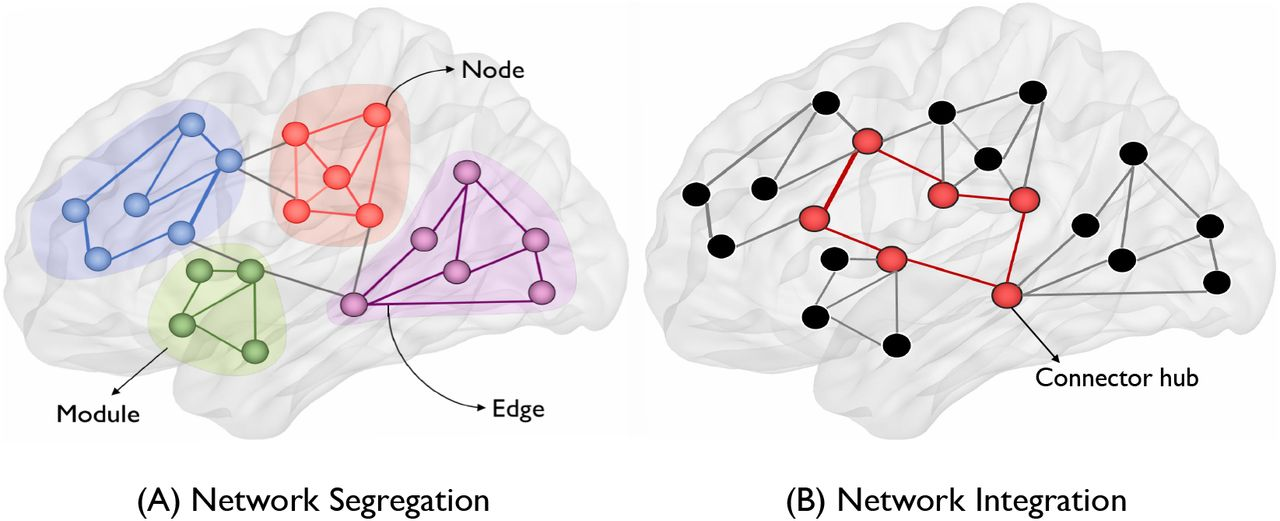



In [1]:
# The most


import pandas as pd
from nilearn import plotting

# Brain atlas centroids
coords = pd.read_csv("coords.txt", header=None)
# Adjacency matrix (brain connectivity)
connectome = pd.read_csv("Conn_mat.txt", header=None)
plotting.view_connectome(connectome.values, coords.values, linewidth=5.0, node_size=5.0)

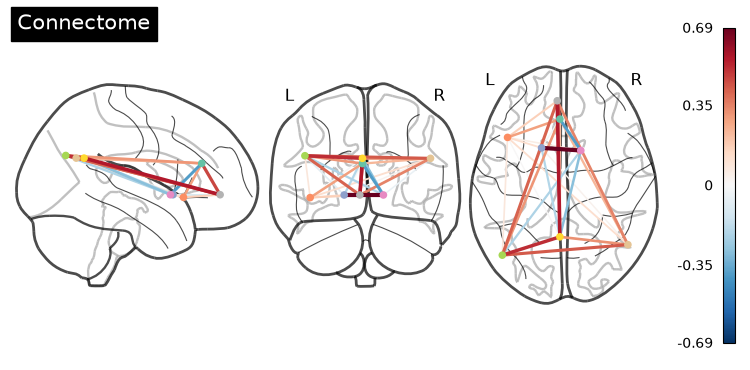

In [2]:
# Static version of the connectome (the interactive 3D view above is not rendered in PDF)
plotting.plot_connectome(connectome.values, coords.values, node_size=20, title="Connectome")
plotting.show()

In [3]:
# Import necessary libraries
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import glob

# Network and TDA Libraries
import networkx as nx

#from nxviz import CircosPlot
#import community


In [4]:
#Load complete connectome and names of the ROIs

#load an averaged FUNCTIONAL connectome into matrix
matrix = np.genfromtxt('AveragedMatrix.txt')

#load lables from Glasser atlas
lineList = [line.rstrip('\n') for line in open('ROI_names.txt')]

#Clean the diagonal
matrixdiagNaN = matrix.copy()
np.fill_diagonal(matrixdiagNaN,np.nan)
Pdmatrix = pd.DataFrame(matrixdiagNaN)
Pdmatrix.columns = lineList
Pdmatrix.index = lineList
Pdmatrix = Pdmatrix.sort_index(axis=0).sort_index(axis=1)


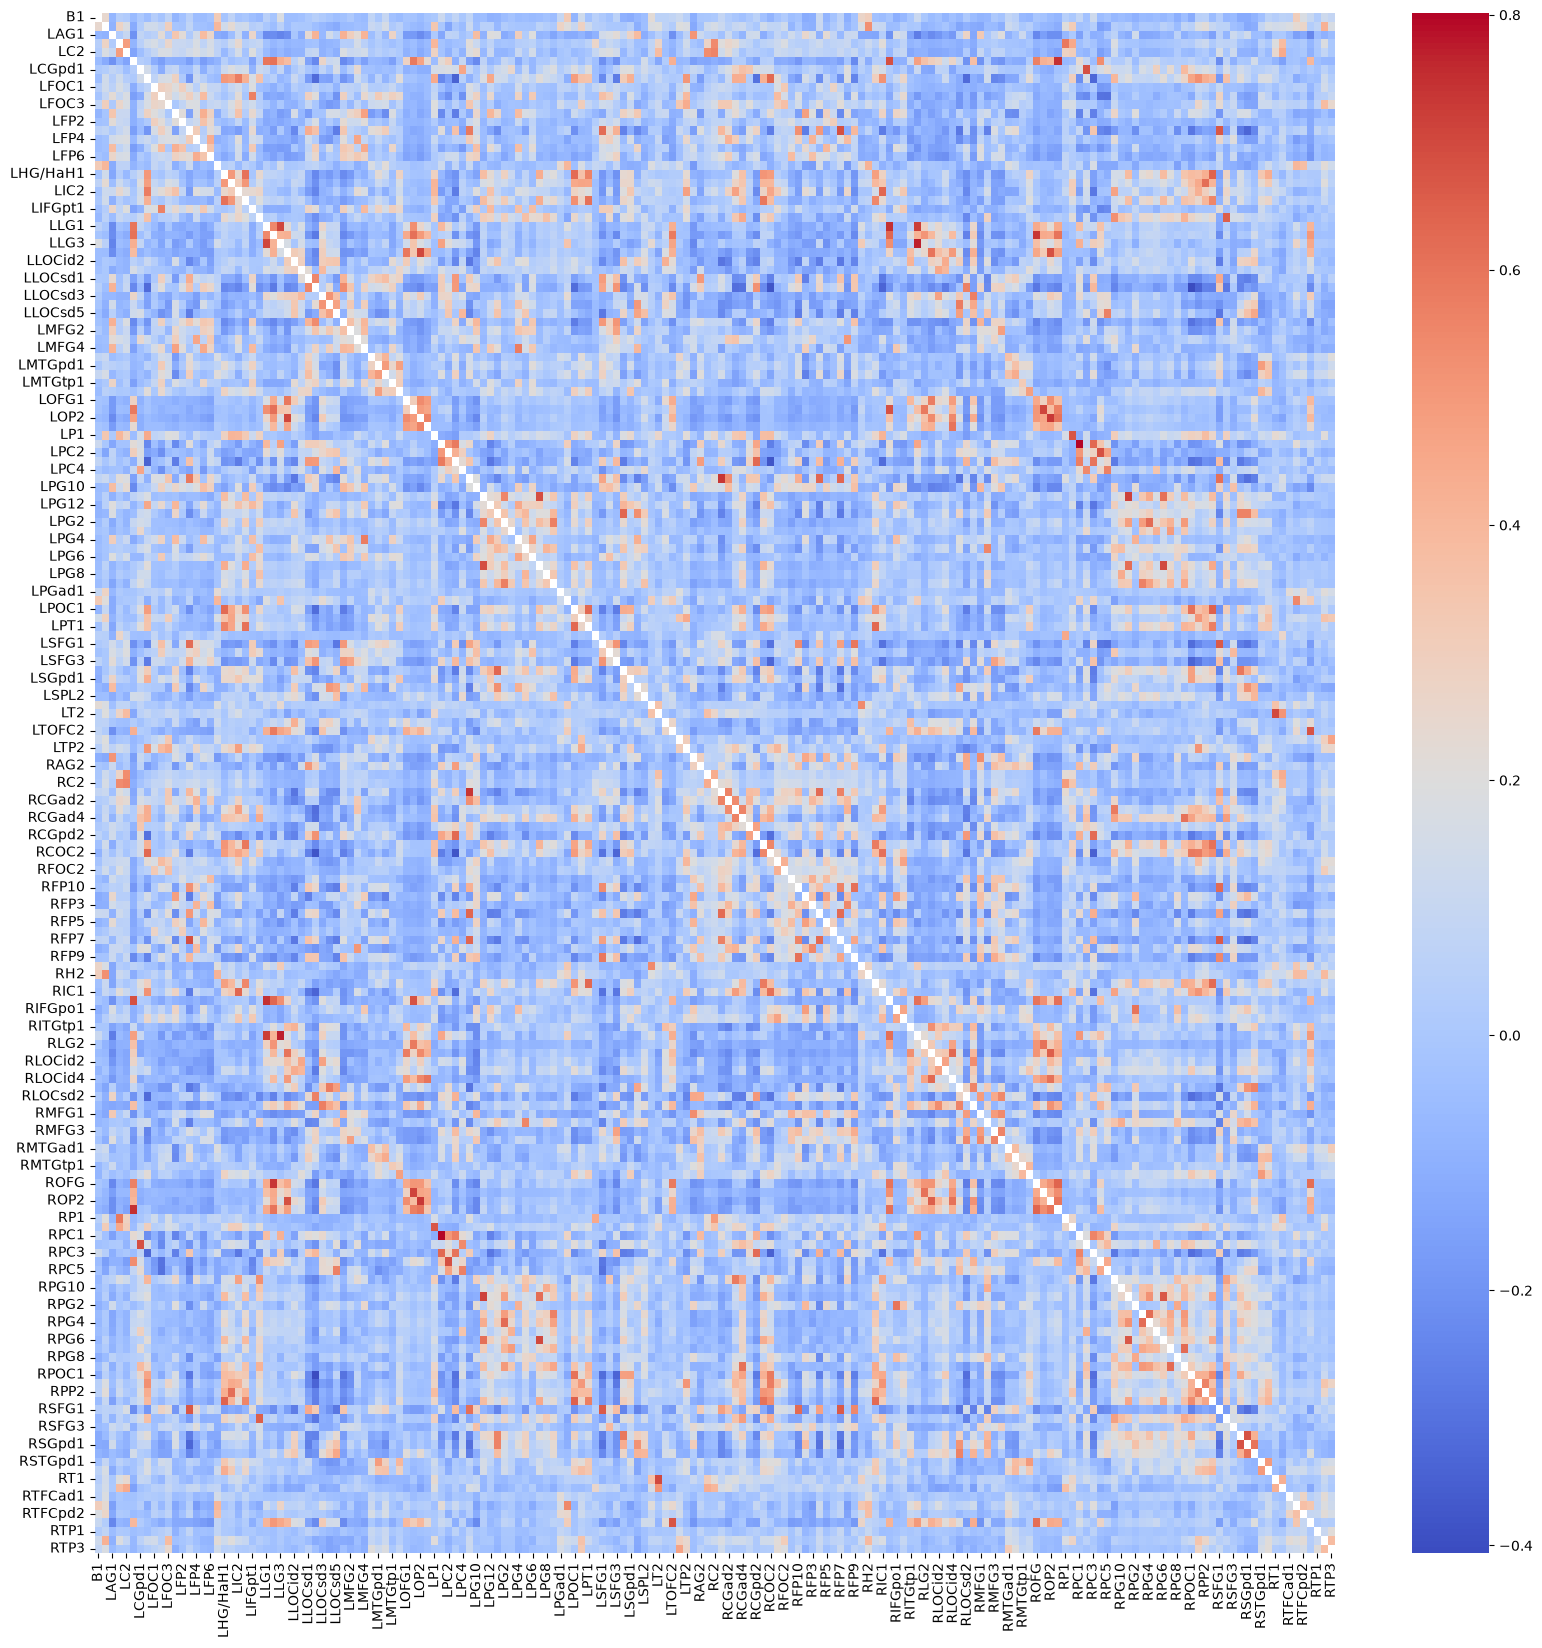

In [5]:
#Plot the functional connectome with lables as a heatmap
# This mask variable gives you the possibility to plot only half of the correlation matrix.
mask = np.zeros_like(Pdmatrix.values, dtype=bool)
mask[np.triu_indices_from(mask)] = True

# This command will show you the functional connectivity matrix with Seaborn
plt.figure(figsize = (20, 20))
_ = sns.heatmap(Pdmatrix, cmap='coolwarm', cbar=True, square=False, mask=None) # To apply the mask, change to

In [6]:
# Make all values absolute for further user (to simplify our lives in this tutorial)
matrix = abs(matrix)
matrixdiagNaN = abs(matrixdiagNaN)


# Most used tools for connectivity metrics are BCTpy and NetworkX

# For NetworkX you need to convert the adjacency matrix in Graph object
# Creating a graph
G = nx.from_numpy_array(matrix)   #nx.from_numpy_matrix(matrix) for the older version

# Removing self-loops (is this needed?)
G.remove_edges_from(list(nx.selfloop_edges(G)))


In [7]:
# Review tradional graph metrics

# Computation of nodal degree/strength
#print(nx.degree.__doc__)

strength = G.degree(weight='weight')
strengths = {node: val for (node, val) in strength}
nx.set_node_attributes(G, dict(strength), 'strength') # Add as nodal attribute

# Normalized node strength values 1/N-1
normstrenghts = {node: val * 1/(len(G.nodes)-1) for (node, val) in strength}
nx.set_node_attributes(G, normstrenghts, 'strengthnorm') # Add as nodal attribute

# Computing the mean degree of the network
normstrengthlist = np.array([val * 1/(len(G.nodes)-1) for (node, val) in strength])
mean_degree = np.sum(normstrengthlist)/len(G.nodes)
print(mean_degree)

0.11425288701460302


Text(0, 0.5, 'Counts')

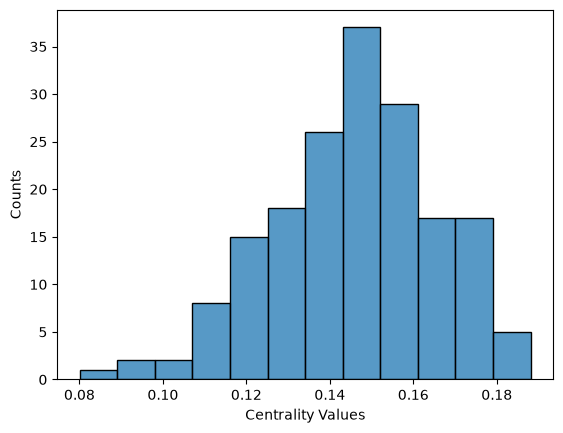

In [8]:
# Closeness centrality
#print(nx.closeness_centrality.__doc__)

# The function accepts a argument 'distance' that, in correlation-based networks, must be seen as the inverse ...
# of the weight value. Thus, a high correlation value (e.g., 0.8) means a shorter distance (i.e., 0.2).
G_distance_dict = {(e1, e2): 1 / abs(weight) for e1, e2, weight in G.edges(data='weight')}

# Then add them as attributes to the graph edges
nx.set_edge_attributes(G, G_distance_dict, 'distance')

# Computation of Closeness Centrality
closeness = nx.closeness_centrality(G, distance='distance')

# Now we add the closeness centrality value as an attribute to the nodes
nx.set_node_attributes(G, closeness, 'closecent')

# Visualise  values directly
#print(closeness)

# Closeness Centrality Histogram
sns.histplot(list(closeness.values()))
plt.xlabel('Centrality Values')
plt.ylabel('Counts')



Text(0, 0.5, 'Counts')

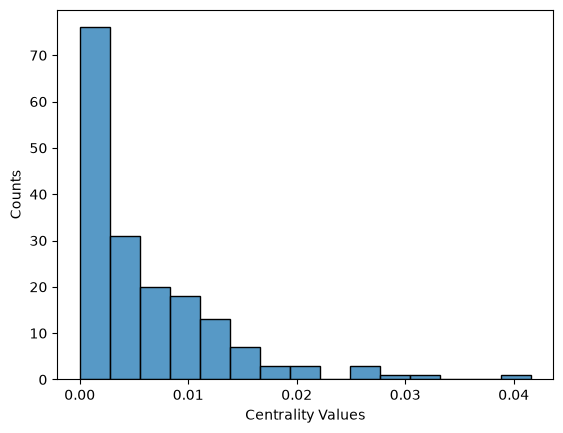

In [9]:

# Betweenness centrality:
#print(nx.betweenness_centrality.__doc__)
betweenness = nx.betweenness_centrality(G, weight='distance', normalized=True)

# Now we add the it as an attribute to the nodes
#nx.set_node_attributes(G, betweenness, 'bc')

# Visualise  values directly
#print(betweenness)

# Betweenness centrality Histogram
sns.histplot(list(betweenness.values()))
plt.xlabel('Centrality Values')
plt.ylabel('Counts')

In [10]:
# Path Length
#print(nx.shortest_path_length.__doc__)

# This one can also be used if defining source and target:
#print(nx.dijkstra_path_length.__doc__)
nx.dijkstra_path_length(G, source=20, target=25, weight='distance')


7.81691095077324

Text(0, 0.5, 'Counts')

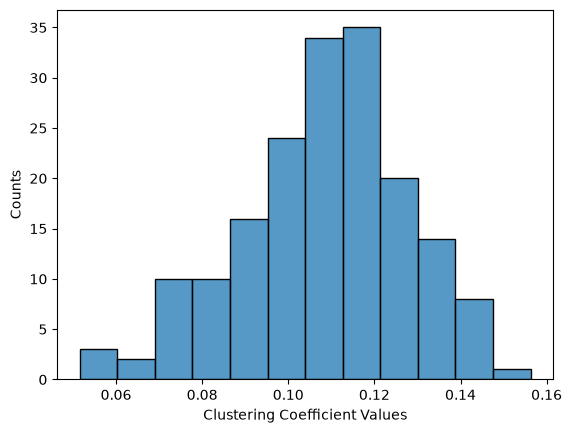

In [11]:
# Clustering Coefficient
#print(nx.clustering.__doc__)
clustering = nx.clustering(G, weight='weight')

# Add as attribute to nodes
nx.set_node_attributes(G, clustering, 'cc')

# Visualise values directly
#print(clustering)

# Clustering Coefficient Histogram
sns.histplot(list(clustering.values()))
plt.xlabel('Clustering Coefficient Values')
plt.ylabel('Counts')